# PS9: YOLO on the Fruits and Vegetables dataset
Dataset: https://www.kaggle.com/datasets/kritikseth/fruit-and-vegetable-image-recognition
Layout: train/, validation/, test/ each with 36 class folders. There are no bounding boxes,
so YOLOv8 is used in classification mode (yolov8n-cls).

Install once: `pip install ultralytics`

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
from ultralytics import YOLO

DATA = Path("../datasets/fruit-and-vegetable-image-recognition")
EPOCHS = 10

In [2]:
# YOLO looks for a folder named "val".
if (DATA / "validation").exists() and not (DATA / "val").exists():
    (DATA / "validation").rename(DATA / "val")

for split in ["train", "val", "test"]:
    classes = sorted(p.name for p in (DATA / split).iterdir() if p.is_dir())
    n = sum(1 for _ in (DATA / split).rglob("*.*"))
    print(f"{split:5s} classes={len(classes)} images={n}")
print(classes)

train classes=36 images=3115
val   classes=36 images=351
test  classes=36 images=359
['apple', 'banana', 'beetroot', 'bell pepper', 'cabbage', 'capsicum', 'carrot', 'cauliflower', 'chilli pepper', 'corn', 'cucumber', 'eggplant', 'garlic', 'ginger', 'grapes', 'jalepeno', 'kiwi', 'lemon', 'lettuce', 'mango', 'onion', 'orange', 'paprika', 'pear', 'peas', 'pineapple', 'pomegranate', 'potato', 'raddish', 'soy beans', 'spinach', 'sweetcorn', 'sweetpotato', 'tomato', 'turnip', 'watermelon']


In [3]:
model = YOLO("yolov8n-cls.pt")
model.train(data=str(DATA.resolve()), epochs=EPOCHS, imgsz=224, seed=42)
save_dir = Path(model.trainer.save_dir)

Ultralytics 8.4.212  Python-3.10.11 torch-2.10.0+cpu CPU (11th Gen Intel Core i7-11800H @ 2.30GHz)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\choud\.cache\kagglehub\datasets\kritikseth\fruit-and-vegetable-image-recognition\versions\8, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto,

train: C:\Users\choud\.cache\kagglehub\datasets\kritikseth\fruit-and-vegetable-image-recognition\versions\8\train... found 3115 images in 36/36 classes  


val: C:\Users\choud\.cache\kagglehub\datasets\kritikseth\fruit-and-vegetable-image-recognition\versions\8\val... found 351 images in 36/36 classes  


test: C:\Users\choud\.cache\kagglehub\datasets\kritikseth\fruit-and-vegetable-image-recognition\versions\8\test... found 359 images in 36/36 classes  


Overriding model.yaml nc=1000 with nc=36


... (2,140 outputs left out)

               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 11/11 2.1s/it 23.4s

                   all      0.917      0.991


Speed: 0.0ms preprocess, 2.2ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to C:\Users\choud\OneDrive\Desktop\deep learning\endsem\PS09_YOLO_Fruits_Vegetables\runs\classify\train


Ultralytics 8.4.212  Python-3.10.11 torch-2.10.0+cpu CPU (11th Gen Intel Core i7-11800H @ 2.30GHz)


YOLOv8n-cls summary (fused): 30 layers, 1,480,996 parameters, 0 gradients, 3.3 GFLOPs


train: C:\Users\choud\.cache\kagglehub\datasets\kritikseth\fruit-and-vegetable-image-recognition\versions\8\train... found 3115 images in 36/36 classes  


val: C:\Users\choud\.cache\kagglehub\datasets\kritikseth\fruit-and-vegetable-image-recognition\versions\8\val... found 351 images in 36/36 classes  


test: C:\Users\choud\.cache\kagglehub\datasets\kritikseth\fruit-and-vegetable-image-recognition\versions\8\test... found 359 images in 36/36 classes  


test: Fast image access  (ping: 0.4±0.1 ms, read: 320.8±234.7 MB/s, size: 1234.9 KB)


... (26 outputs left out)

                   all      0.919      0.992


Speed: 0.0ms preprocess, 1.9ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to C:\Users\choud\OneDrive\Desktop\deep learning\endsem\PS09_YOLO_Fruits_Vegetables\runs\classify\val


Test top-1 accuracy: 0.9192   Test top-5 accuracy: 0.9916


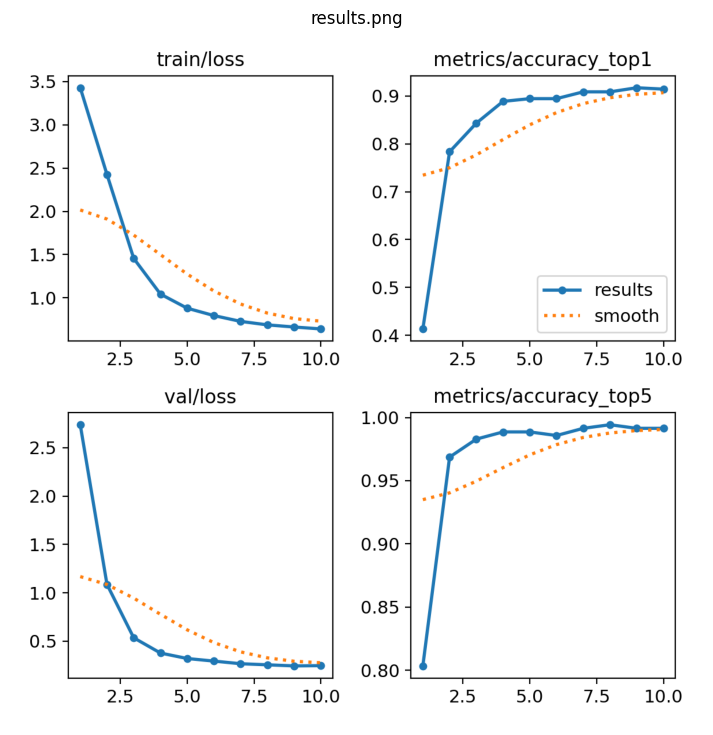

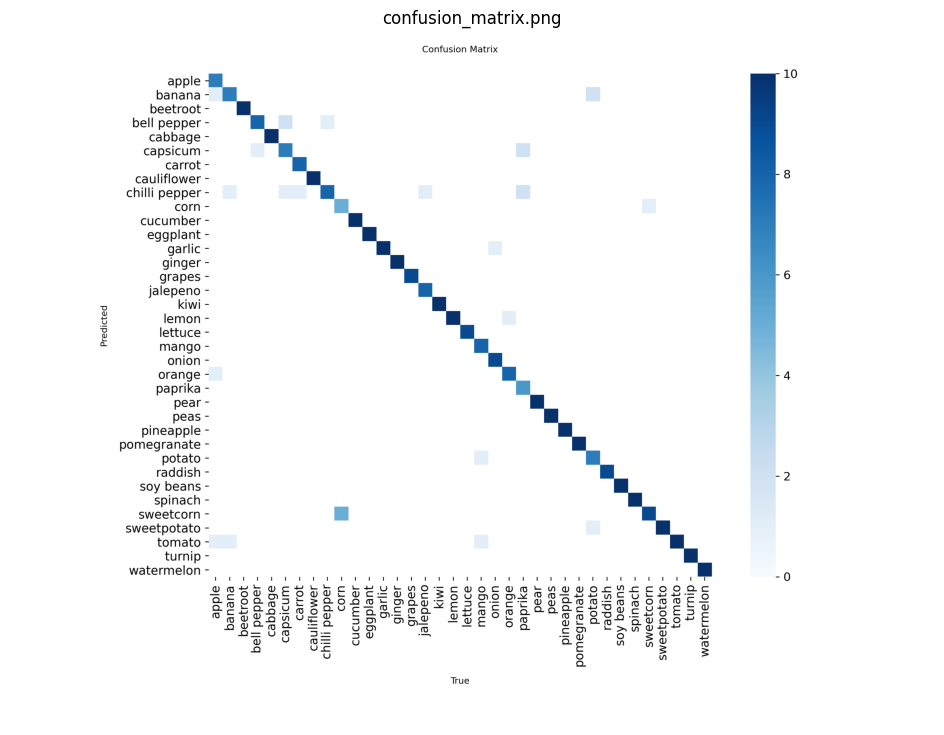

In [4]:
metrics = model.val(data=str(DATA.resolve()), split="test")
print(f"Test top-1 accuracy: {metrics.top1:.4f}   Test top-5 accuracy: {metrics.top5:.4f}")

for name in ["results.png", "confusion_matrix.png"]:
    plt.figure(figsize=(14, 9))
    plt.imshow(plt.imread(save_dir / name))
    plt.title(name)
    plt.axis("off")
    plt.show()

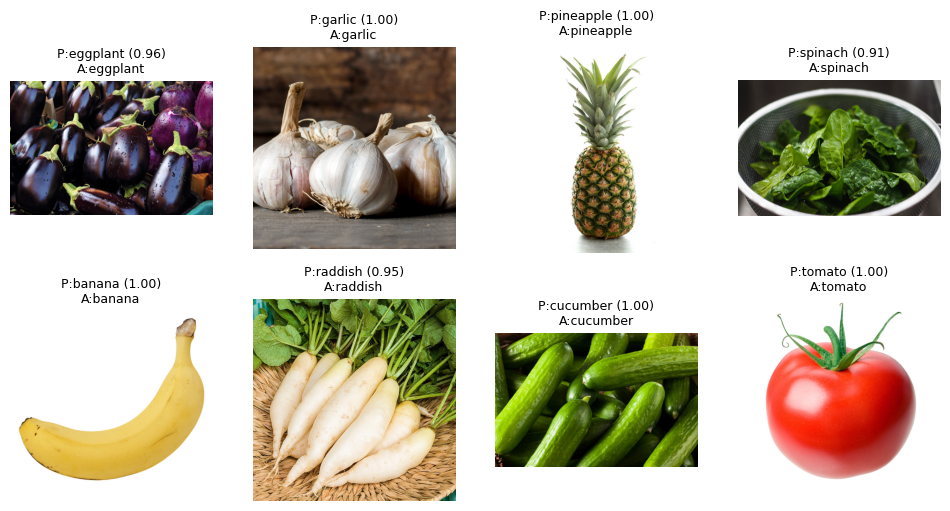

In [5]:
test_images = sorted((DATA / "test").rglob("*.*"))
plt.figure(figsize=(12, 6))
for i, img in enumerate(random.sample(test_images, 8)):
    r = model.predict(str(img), verbose=False)[0]
    plt.subplot(2, 4, i + 1)
    plt.imshow(r.orig_img[..., ::-1])
    plt.title(f"P:{r.names[r.probs.top1]} ({r.probs.top1conf:.2f})\nA:{img.parent.name}", fontsize=9)
    plt.axis("off")
plt.show()